# Test-Set Evaluation: EfficientNetB0 AMD vs Non-AMD

This notebook loads the best completed EfficientNetB0 checkpoint and evaluates it once on the untouched patient-level test split. It does not retrain, tune, modify raw data, or change split membership.

All evaluation artifacts are saved under `results/evaluation/`.

## 1. Evaluation scope and limitations

The test set is used only here, after training and model selection are complete. Metrics describe this held-out OCTDL sample and should not be interpreted as clinical validation or prospective patient performance.

## 2. Imports and paths

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import efficientnet_b0

def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "raw" / "OCTDL").is_dir():
            return candidate
    raise FileNotFoundError("Could not find project root containing data/raw/OCTDL.")

PROJECT_ROOT = find_project_root()
SRC_ROOT = PROJECT_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))
from oct_preprocessing import preprocess_image

PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"
CHECKPOINT_PATH = PROJECT_ROOT / "models" / "baseline_efficientnetb0_best.pth"
EVALUATION_ROOT = PROJECT_ROOT / "results" / "evaluation"
PLOT_ROOT = EVALUATION_ROOT / "plots"
EVALUATION_ROOT.mkdir(parents=True, exist_ok=True)
PLOT_ROOT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
print(f"Device: {DEVICE}")
print(f"Checkpoint exists: {CHECKPOINT_PATH.is_file()}")
print(f"Evaluation output: {EVALUATION_ROOT}")

Device: cpu
Checkpoint exists: True
Evaluation output: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\results\evaluation


## 3. Load only the untouched test dataset

No training or validation loader is created in this notebook. Images remain dynamically loaded from their original paths.

In [2]:
TEST_PATH = PROCESSED_ROOT / "test.csv"
if not TEST_PATH.is_file():
    raise FileNotFoundError(f"Test split not found: {TEST_PATH}")
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Model checkpoint not found: {CHECKPOINT_PATH}")

test_frame = pd.read_csv(TEST_PATH)
test_frame["image_path_absolute"] = test_frame["image_path"].map(lambda value: PROJECT_ROOT / str(value))
if not test_frame["image_path_absolute"].map(Path.is_file).all():
    raise FileNotFoundError("At least one test image path is missing.")
print(f"Test images: {len(test_frame):,}")
print(f"Test patients: {test_frame['patient_id'].nunique():,}")
print(f"Test labels: {test_frame['target_amd'].value_counts().sort_index().to_dict()}")

Test images: 307
Test patients: 123
Test labels: {0: 133, 1: 174}


## 4. Reconstruct the baseline model and load the best checkpoint

In [3]:
class OCTTestDataset(Dataset):
    def __init__(self, frame: pd.DataFrame):
        self.frame = frame.reset_index(drop=True).copy()

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        record = self.frame.iloc[index]
        array = preprocess_image(record["image_path_absolute"], augment=False)
        image = torch.from_numpy(array).float()
        label = torch.tensor(float(record["target_amd"]), dtype=torch.float32)
        return image, label

test_dataset = OCTTestDataset(test_frame)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model = efficientnet_b0(weights=None)
for parameter in model.features.parameters():
    parameter.requires_grad = False
classifier_input_features = model.classifier[1].in_features
model.classifier = nn.Sequential(nn.Dropout(p=0.30), nn.Linear(classifier_input_features, 1))
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()
print(f"Loaded checkpoint epoch: {checkpoint.get('epoch', 'unknown')}")
print(f"Checkpoint validation metrics: {checkpoint.get('validation_metrics', {})}")
print(f"Test input shape: {tuple(next(iter(test_loader))[0].shape)}")

Loaded checkpoint epoch: 12
Checkpoint validation metrics: {'accuracy': 0.8318042813455657, 'precision': 0.8585858585858586, 'recall': 0.8629441624365483, 'f1': 0.8607594936708861, 'roc_auc': 0.905193283873487}


Test input shape: (16, 3, 224, 224)


## 5. Evaluate once on the held-out test set

The model is kept in evaluation mode. No gradients, optimizer, or test-time augmentation are used.

In [4]:
all_labels, all_probabilities = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        logits = model(images).squeeze(1)
        probabilities = torch.sigmoid(logits)
        all_labels.extend(labels.numpy().astype(int).tolist())
        all_probabilities.extend(probabilities.cpu().numpy().tolist())

labels_array = np.asarray(all_labels, dtype=int)
probabilities_array = np.asarray(all_probabilities, dtype=float)
predictions_array = (probabilities_array >= 0.5).astype(int)

test_metrics = {
    "accuracy": accuracy_score(labels_array, predictions_array),
    "precision": precision_score(labels_array, predictions_array, zero_division=0),
    "recall": recall_score(labels_array, predictions_array, zero_division=0),
    "f1_score": f1_score(labels_array, predictions_array, zero_division=0),
    "roc_auc": roc_auc_score(labels_array, probabilities_array) if len(np.unique(labels_array)) == 2 else float("nan"),
}

print("TEST SET METRICS")
print("-" * 24)
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.6f}")

TEST SET METRICS
------------------------
accuracy: 0.846906
precision: 0.854749
recall: 0.879310
f1_score: 0.866856
roc_auc: 0.922003


## 6. Save classification report and confusion matrix

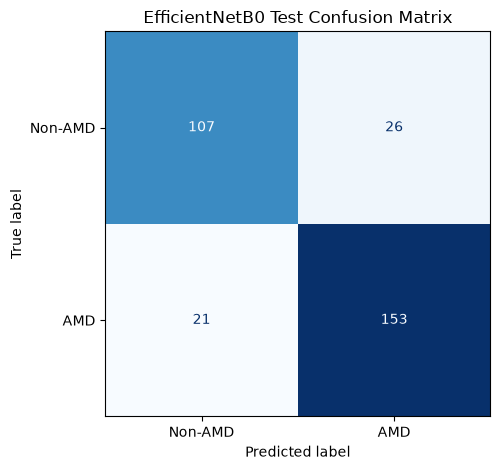

Saved classification report and confusion matrix to C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\results\evaluation


In [5]:
class_names = ["Non-AMD", "AMD"]
report_dict = classification_report(labels_array, predictions_array, target_names=class_names, output_dict=True, zero_division=0)
report_table = pd.DataFrame(report_dict).T
report_table.to_csv(EVALUATION_ROOT / "classification_report.csv")
with (EVALUATION_ROOT / "classification_report.txt").open("w", encoding="utf-8") as handle:
    handle.write(classification_report(labels_array, predictions_array, target_names=class_names, zero_division=0))

matrix = confusion_matrix(labels_array, predictions_array, labels=[0, 1])
pd.DataFrame(matrix, index=class_names, columns=class_names).to_csv(EVALUATION_ROOT / "confusion_matrix.csv")
figure, axis = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=class_names).plot(ax=axis, cmap="Blues", colorbar=False, values_format="d")
axis.set_title("EfficientNetB0 Test Confusion Matrix")
figure.tight_layout()
figure.savefig(EVALUATION_ROOT / "confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved classification report and confusion matrix to {EVALUATION_ROOT}")

## 7. ROC curve and AUC

ROC-AUC is calculated from continuous AMD probabilities, not thresholded predictions.

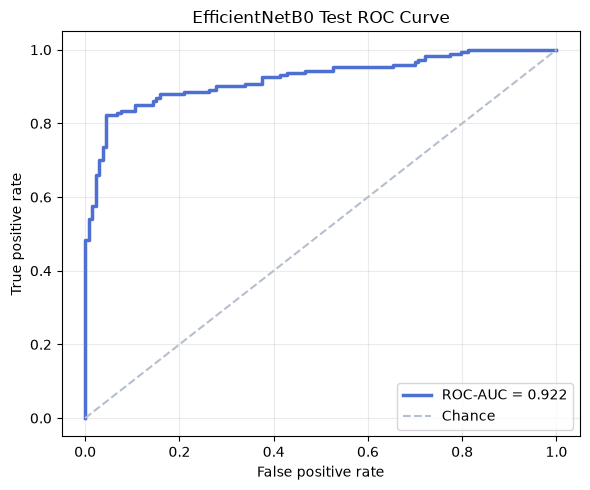

Saved ROC curve: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\results\evaluation\plots\test_roc_curve.png


In [6]:
if len(np.unique(labels_array)) == 2:
    false_positive_rate, true_positive_rate, thresholds = roc_curve(labels_array, probabilities_array)
    figure, axis = plt.subplots(figsize=(6, 5))
    axis.plot(false_positive_rate, true_positive_rate, color="#4f70d3", linewidth=2.5, label=f"ROC-AUC = {test_metrics['roc_auc']:.3f}")
    axis.plot([0, 1], [0, 1], color="#b5bfce", linestyle="--", label="Chance")
    axis.set_xlabel("False positive rate")
    axis.set_ylabel("True positive rate")
    axis.set_title("EfficientNetB0 Test ROC Curve")
    axis.legend(loc="lower right")
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(PLOT_ROOT / "test_roc_curve.png", dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved ROC curve: {PLOT_ROOT / 'test_roc_curve.png'}")
else:
    print("ROC curve skipped because the test labels contain only one class.")

## 8. Save evaluation summary

This final table records the held-out test metrics and checkpoint provenance.

In [7]:
summary = {
    "checkpoint": str(CHECKPOINT_PATH.relative_to(PROJECT_ROOT)),
    "checkpoint_epoch": checkpoint.get("epoch"),
    "test_images": len(test_frame),
    "test_patients": test_frame["patient_id"].nunique(),
    **test_metrics,
}
pd.DataFrame([summary]).to_csv(EVALUATION_ROOT / "test_metrics.csv", index=False)
print("EVALUATION COMPLETE")
print("-" * 24)
for key, value in summary.items():
    print(f"{key}: {value}")
print("Test evaluation was performed once; no retraining or tuning occurred.")

EVALUATION COMPLETE
------------------------
checkpoint: models\baseline_efficientnetb0_best.pth
checkpoint_epoch: 12
test_images: 307
test_patients: 123
accuracy: 0.8469055374592834
precision: 0.8547486033519553
recall: 0.8793103448275862
f1_score: 0.8668555240793201
roc_auc: 0.9220032840722495
Test evaluation was performed once; no retraining or tuning occurred.
